# AUV DVL–IMU Navigation: Consolidated Simulation Study
**From Doppler physics to fault-tolerant INS/DVL navigation at 3800 m and 6000 m**

**Author:** Tejas Jadhav, B.Tech Mechatronics Engineering, Symbiosis Skills and Professional University  
**Date:** 21 October 2026 · **Version:** 1.0

This notebook replaces the earlier 94-cell exploratory notebook. Every experiment shares **one configuration,
one signal model, one 9-state EKF and one fault-detection routine**, so results are directly comparable.

| Part | Experiments | Question answered |
|---|---|---|
| **A. DVL measurement** | A1 Doppler & noise · A2 Beam geometry & observability · A3 Echo processing (FFT vs pulse-pair) | How good is one DVL measurement? |
| **B. Navigation** | B1 INS vs INS+DVL · B2 Dropout & outages · B3 Update rate × IMU bias · B4 Online bias estimation · B5 Realistic hardware noise | How much does the DVL fix inertial drift? |
| **C. Fault tolerance** | C1 Residual calibration (fixes old Exp 26/26B) · C2 Single-beam fault detection · C3 Permanent beam failures · C4 Outliers & intermittent faults | Can the system detect and survive bad beams? |
| **D. Deep water** | D1 Ocean environment · D2 Sound-speed error · D3 Bottom-lock range vs frequency · D4 3800/6000 m mission error budget · D5 Pressure housing sizing | What changes at Titanic depth and 6000 m? |
| **E. Summary** | All headline numbers in one table | |

**Corrections relative to the old notebook**
1. Beam residuals are normalised with the *actual* EKF covariance at the DVL epoch, `σ² = bᵢᵀ P_v⁻ bᵢ + σ_r²`. Normalising with σ_r alone reproduces the excessive false-alarm rate seen in old Exp 26/26B (shown in C1).
2. Absolute position is **not** observable from a DVL. After an outage, velocity recovers within about 1 s, but the position error built up during the outage stays (B2). The old claim that the solution "recovers" referred to velocity only.
3. The EKF uses the canonical architecture from the review: state `[p, v, b_a]` with four radial-beam measurements, not a pre-computed 3-D velocity.

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt, time
from dataclasses import dataclass, replace
from math import erfc, sqrt

PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#4a3aa7", "#e34948"]
plt.rcParams.update({
    "figure.figsize": (9, 4.2), "figure.dpi": 110, "axes.prop_cycle": plt.cycler(color=PALETTE),
    "axes.grid": True, "grid.color": "#e6e5e0", "grid.linewidth": 0.6, "axes.spines.top": False,
    "axes.spines.right": False, "axes.edgecolor": "#8a8984", "lines.linewidth": 2, "lines.markersize": 6,
    "font.size": 10, "axes.titlesize": 11, "axes.titleweight": "bold", "legend.frameon": False})
pd.set_option("display.precision", 4)

RESULTS = []   # (experiment, metric, value) — collected for the summary table in Part E
def record(exp, metric, value):
    RESULTS.append((exp, metric, value)); print(f"[{exp}] {metric}: {value}")

## 0. Configuration and core library
Every experiment uses these defaults and overrides only what it is studying.

In [2]:
@dataclass(frozen=True)
class Cfg:
    f0: float = 1.0e6          # carrier frequency [Hz]
    c: float = 1500.0          # sound speed assumed by the DVL [m/s]
    theta_deg: float = 30.0    # Janus beam angle from vertical
    imu_rate: float = 100.0    # [Hz]
    dvl_rate: float = 5.0      # [Hz]
    T: float = 60.0            # mission length for Parts B/C [s]
    sigma_acc: float = 0.02    # accelerometer white noise per sample [m/s²]
    sigma_bias: float = 0.005  # accelerometer bias 1σ per axis [m/s²] (~0.5 mg, MEMS)
    q_bias: float = 1e-8       # bias random-walk PSD used by the filter
    noise_hz: float = 10.0     # per-beam Doppler noise [Hz]
CFG = Cfg()

def beam_matrix(theta_deg=30.0):
    s, c = np.sin(np.radians(theta_deg)), np.cos(np.radians(theta_deg))
    return np.array([[s, 0, c], [-s, 0, c], [0, s, c], [0, -s, c]])   # rows = unit beam vectors (z down)
B = beam_matrix(CFG.theta_deg)

doppler_shift   = lambda v_r, f0=CFG.f0, c=CFG.c: 2 * f0 * v_r / c
radial_velocity = lambda f_d, f0=CFG.f0, c=CFG.c: c * f_d / (2 * f0)
sigma_v_from_hz = lambda hz, f0=CFG.f0, c=CFG.c: c * hz / (2 * f0)

def truth_trajectory(T, dt):
    """Smooth 3-D manoeuvre. Truth is integrated with the same discrete kinematics the INS uses,
    so every navigation error comes from sensor errors, not from discretisation."""
    t = np.arange(0, T + 1e-9, dt)
    a = np.stack([0.20 * np.sin(2 * np.pi * t / 20), 0.10 * np.cos(2 * np.pi * t / 15),
                  0.05 * np.sin(2 * np.pi * t / 30)], 1)
    v = np.zeros_like(a); p = np.zeros_like(a); v[0] = [1.0, 0.4, 0.2]
    for k in range(len(t) - 1):
        p[k + 1] = p[k] + v[k] * dt + 0.5 * a[k] * dt**2
        v[k + 1] = v[k] + a[k] * dt
    return t, a, v, p

### Batched INS/DVL EKF with beam-level fault detection and isolation (FDI)
* **State:** `x = [p(3), v(3), b_a(3)]`. **Prediction:** bias-compensated IMU at 100 Hz.
* **Measurement:** four radial velocities `z_i = b_iᵀ v + n_i`, applied as sequential scalar updates.
* **FDI:** before the update, compute each beam's normalised residual `z_i = (z_i − b_iᵀ v̂⁻) / sqrt(b_iᵀ P_v⁻ b_i + σ_r²)`. Any beam with `|z_i| > k` is excluded. The remaining beams update the filter, even if only one or two are left: the INS covers the missing directions.
* **Quarantine:** a beam that is flagged in 2 of the last 3 epochs is treated as persistently faulty and kept out for `hold_s` = 2 s, until its residuals stay below the threshold. A single flag (an outlier) rejects only that one epoch, so no good data is thrown away. Without quarantine, one missed detection lets the filter absorb part of a persistent fault, and isolation decays over time (see C2).
* Runs `N` Monte-Carlo trials in parallel (vectorised), so the sweeps stay fast.

In [3]:
def fault_active(fault, tk):
    if fault is None or not (fault["t_start"] <= tk < fault.get("t_end", np.inf)):
        return False
    if "period" in fault:   # intermittent: on for `on` seconds every `period`
        return ((tk - fault["t_start"]) % fault["period"]) < fault["on"]
    return True

def run_nav(N=100, cfg=CFG, seed=0, T=None, dvl=True, dvl_rate=None, noise_hz=None, R_hz=None,
            bias_sigma=None, estimate_bias=True, dropout=0.0, outage=None, failed_beams=(), t_fail=10.0,
            fault=None, outlier_p=0.0, outlier_mag=0.5, fdi=True, k_sigma=4.0, norm="ekf", hold_s=2.0):
    rng = np.random.default_rng(seed)
    dt = 1 / cfg.imu_rate; T = cfg.T if T is None else T
    dvl_rate = cfg.dvl_rate if dvl_rate is None else dvl_rate
    noise_hz = cfg.noise_hz if noise_hz is None else noise_hz
    R_hz = noise_hz if R_hz is None else R_hz
    bias_sigma = cfg.sigma_bias if bias_sigma is None else bias_sigma
    sig_r, sig_R = sigma_v_from_hz(noise_hz, cfg.f0, cfg.c), sigma_v_from_hz(R_hz, cfg.f0, cfg.c)
    t, a, v, p = truth_trajectory(T, dt); K = len(t); n_dvl = int(round(cfg.imu_rate / dvl_rate))

    b_true = rng.normal(0, bias_sigma, (N, 3))
    I3 = np.eye(3)
    F = np.eye(9); F[0:3, 3:6] = I3 * dt; F[0:3, 6:9] = -0.5 * I3 * dt**2; F[3:6, 6:9] = -I3 * dt
    G = np.zeros((9, 3)); G[0:3] = 0.5 * I3 * dt**2; G[3:6] = I3 * dt
    Q = G @ G.T * cfg.sigma_acc**2
    pb = bias_sigma**2 if estimate_bias else 0.0
    if estimate_bias: Q[6:9, 6:9] = I3 * cfg.q_bias * dt
    x = np.zeros((N, 9))
    x[:, 0:3] = p[0] + rng.normal(0, 0.01, (N, 3)); x[:, 3:6] = v[0] + rng.normal(0, 0.05, (N, 3))
    P = np.tile(np.diag([1e-4] * 3 + [0.05**2] * 3 + [pb] * 3), (N, 1, 1))
    H = np.zeros((4, 9)); H[:, 3:6] = B

    pos_err = np.zeros((N, K, 3)); vel_err = np.zeros((N, K, 3)); bias_est = np.zeros((N, K, 3))
    ep = dict(t=[], z=[], flag=[], excl=[], avail=[], faulty=[])
    hold = int(round(hold_s * dvl_rate)); quar = np.zeros((N, 4), int); hist = np.zeros((N, 4), int)
    for k in range(K):
        if k > 0:   # --- INS prediction
            a_m = a[k - 1] + b_true + rng.normal(0, cfg.sigma_acc, (N, 3))
            acc = a_m - x[:, 6:9]
            x[:, 0:3] += x[:, 3:6] * dt + 0.5 * acc * dt**2
            x[:, 3:6] += acc * dt
            P = F @ P @ F.T + Q
        if dvl and k > 0 and k % n_dvl == 0:   # --- DVL epoch
            tk = t[k]
            zr = (B @ v[k])[None, :] + rng.normal(0, sig_r, (N, 4))
            avail = rng.random((N, 4)) >= dropout
            if outage and outage[0] <= tk < outage[1]: avail[:] = False
            if len(failed_beams) and tk >= t_fail: avail[:, list(failed_beams)] = False
            faulty = np.zeros((N, 4), bool)
            if fault_active(fault, tk):
                fb = fault["beams"]; faulty[np.arange(N), fb] = True
                zr[np.arange(N), fb] += fault["mag"]
            if outlier_p > 0:
                om = rng.random((N, 4)) < outlier_p
                zr += om * outlier_mag * rng.choice([-1, 1], (N, 4)); faulty |= om
            r = zr - x[:, 3:6] @ B.T
            var_pred = np.einsum("ij,njk,ik->ni", B, P[:, 3:6, 3:6], B)
            S = var_pred + sig_R**2 if norm == "ekf" else np.full((N, 4), sig_R**2)
            z = r / np.sqrt(S)
            flag = avail & (np.abs(z) > k_sigma) if fdi else np.zeros((N, 4), bool)
            excl = flag | (avail & (quar > 0))                 # a flagged beam is always rejected this epoch
            hist = ((hist << 1) | flag) & 0b111                # flags in the last 3 epochs
            persistent = (hist & 1).astype(bool) & (((hist >> 0) & 1) + ((hist >> 1) & 1) + ((hist >> 2) & 1) >= 2)
            quar = np.where(persistent, hold, np.where(flag, quar, np.maximum(quar - 1, 0)))  # quarantine only repeated flags
            use = avail & ~excl
            for i in range(4):          # sequential scalar updates
                h = H[i]; m = use[:, i]
                if not m.any(): continue
                Ph = P @ h; s_i = Ph @ h + sig_R**2; Kg = Ph / s_i[:, None]
                y = zr[:, i] - x @ h
                x += (m * y)[:, None] * Kg
                P -= m[:, None, None] * Kg[:, :, None] * Ph[:, None, :]
            P = 0.5 * (P + P.transpose(0, 2, 1))
            for key, val in zip(["t", "z", "flag", "excl", "avail", "faulty"], [tk, z, flag, excl, avail, faulty]):
                ep[key].append(val)
        pos_err[:, k] = x[:, 0:3] - p[k]; vel_err[:, k] = x[:, 3:6] - v[k]; bias_est[:, k] = x[:, 6:9] - b_true
    out = dict(t=t, pos_err=pos_err, vel_err=vel_err, bias_err=bias_est, b_true=b_true)
    if ep["t"]:
        out["ep_t"] = np.array(ep["t"])
        for key in ["z", "flag", "excl", "avail", "faulty"]:
            out[key] = np.stack(ep[key], 1)   # (N, E, 4)
    return out

rms3 = lambda e: np.sqrt(np.mean(np.sum(e**2, -1), 0))          # RMS over trials of 3-D error norm, vs time
final_rmse = lambda o, key="pos_err": rms3(o[key])[-1]

---
# Part A — DVL measurement physics
## A1. Doppler conversion and noise mapping (old Exp 1–2)
For a radial velocity `v_r`: `f_D = 2 f₀ v_r / c`. The Doppler noise maps linearly to velocity noise: `σ_v = c σ_f / (2 f₀)`.

In [4]:
fD = doppler_shift(0.5)
record("A1", "Doppler shift for v_r = 0.5 m/s @ 1 MHz", f"{fD:.3f} Hz")
rng = np.random.default_rng(1)
rows = []
for hz in [2, 5, 10, 20, 40]:
    est = radial_velocity(fD + rng.normal(0, hz, 200_000))
    rows.append(dict(noise_Hz=hz, sigma_v_theory=sigma_v_from_hz(hz), sigma_v_MC=est.std(), bias_MC=est.mean() - 0.5))
dfA1 = pd.DataFrame(rows); display(dfA1)
record("A1", "σ_v for 10 Hz Doppler noise", f"{sigma_v_from_hz(10):.4f} m/s (MC {dfA1.sigma_v_MC[2]:.4f})")

[A1] Doppler shift for v_r = 0.5 m/s @ 1 MHz: 666.667 Hz


,noise_Hz,sigma_v_theory,sigma_v_MC,bias_MC
0,2,0.0015,0.0015,-3.7251e-06
1,5,0.0037,0.0037,-1.1698e-05
2,10,0.0075,0.0075,1.1079e-05
3,20,0.0150,0.0150,4.5182e-06
4,40,0.0300,0.0299,8.3387e-05


[A1] σ_v for 10 Hz Doppler noise: 0.0075 m/s (MC 0.0075)


## A2. Janus geometry, reconstruction and observability (old Exp 3, 20)
Least squares `V̂ = (BᵀB)⁻¹ Bᵀ v_r`. Observability needs `rank(B) = 3`. The condition number κ measures how much noise is amplified.

,,count,min,max
n,rank,,,
2,2,6,inf,inf
3,3,4,3.8208,3.8208
4,3,1,2.4495,2.4495


[A2] κ(4 beams) / κ(3 beams): 2.449 / 3.821; 2 beams → rank 2 (unobservable alone)
[A2] LS reconstruction RMSE [Vx,Vy,Vz] @10 Hz: [0.01065 0.01059 0.00433]


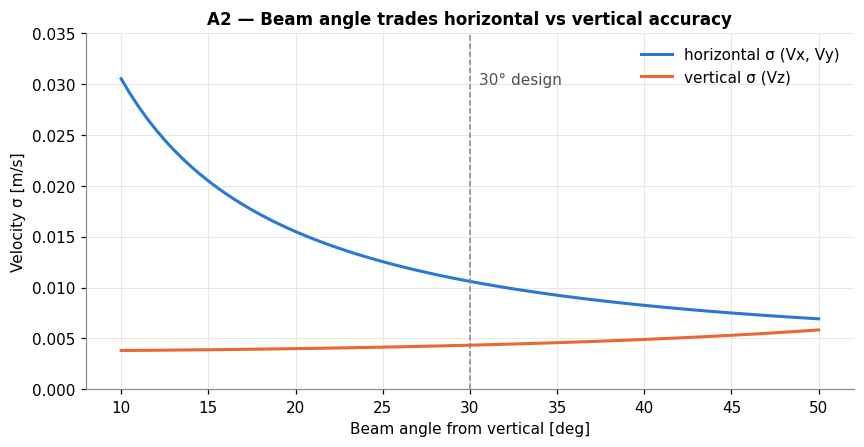

In [5]:
from itertools import combinations
rows = []
for n in [4, 3, 2]:
    for sub in combinations(range(4), n):
        Bs = B[list(sub)]; sv = np.linalg.svd(Bs, compute_uv=False)
        rows.append(dict(beams=str([s + 1 for s in sub]), n=n, rank=np.linalg.matrix_rank(Bs),
                         cond=sv[0] / sv[-1] if np.linalg.matrix_rank(Bs) == 3 else np.inf))
dfA2 = pd.DataFrame(rows).drop_duplicates("beams"); display(dfA2.groupby(["n", "rank"]).cond.agg(["count", "min", "max"]))
record("A2", "κ(4 beams) / κ(3 beams)", f"{dfA2[dfA2.n==4].cond.iloc[0]:.3f} / {dfA2[dfA2.n==3].cond.iloc[0]:.3f}; 2 beams → rank 2 (unobservable alone)")

V = np.array([1.0, 0.4, 0.2]); sr = sigma_v_from_hz(10)
vr = B @ V + rng.normal(0, sr, (100_000, 4))
Vh = np.linalg.lstsq(B, vr.T, rcond=None)[0].T
rmse_axes = np.sqrt(np.mean((Vh - V)**2, 0))
record("A2", "LS reconstruction RMSE [Vx,Vy,Vz] @10 Hz", np.array2string(rmse_axes, precision=5))

th = np.linspace(10, 50, 81); s_r = sr
fig, ax = plt.subplots()
ax.plot(th, s_r / (np.sqrt(2) * np.sin(np.radians(th))), label="horizontal σ (Vx, Vy)")
ax.plot(th, s_r / (2 * np.cos(np.radians(th))), label="vertical σ (Vz)")
ax.axvline(30, color="#8a8984", ls="--", lw=1); ax.text(30.5, 0.03, "30° design", color="#52514e")
ax.set(xlabel="Beam angle from vertical [deg]", ylabel="Velocity σ [m/s]", title="A2 — Beam angle trades horizontal vs vertical accuracy", ylim=(0, 0.035))
ax.legend(); plt.show()

## A3. Seabed echo processing: FFT vs pulse-pair (old Exp 4–7)
This is a more physical echo model than the old single-tone version, and it matches what the planned hardware digitises after I/Q demodulation:
* Baseband (I/Q) at 40 kS/s with a 2 ms pulse.
* 300 seabed scatterers spread across a 4° beam footprint. Each has its own range, its own Doppler (from its angle) and a random phase, which produces **speckle** and **Doppler spread**.

Estimators compared:
* **FFT peak:** zero-padded, with parabolic interpolation.
* **Pulse-pair, lag 1:** `f = ∠R(1)·fs/2π`.
* **Dual-lag pulse-pair:** a lag-8 estimate for precision, unwrapped using the lag-1 estimate. This is cheap enough for an STM32.

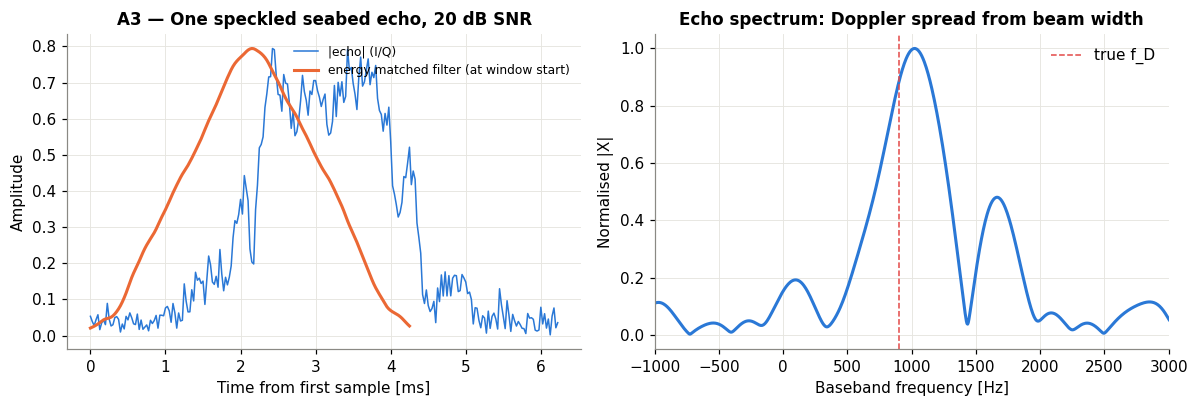

True altitude 20.0 m → estimated 20.02 m | true f_D 897.6 Hz → FFT 904.5, PP1 1016.4, PP8 1018.1 Hz


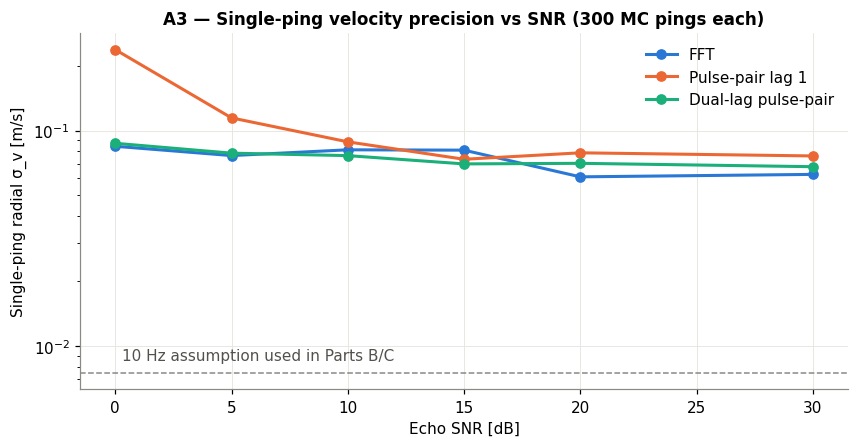

[A3] Single-ping σ_f at 20 dB (dual-lag PP): 94.0 Hz → ~89 pings averaged per beam to reach 10 Hz
[A3] Altitude RMSE at 20 dB (MF): 0.211 m @ 20 m


In [6]:
def tukey(n, alpha=0.1):
    w = np.ones(n); m = int(alpha * n / 2)
    if m: ramp = 0.5 * (1 - np.cos(np.pi * np.arange(m) / m)); w[:m] = ramp; w[-m:] = ramp[::-1]
    return w

def simulate_echo(v, beam, altitude, snr_db, rng, f0=1e6, c=1500.0, fs=40e3, tau=2e-3, beam_deg=4.0, n_scat=300):
    b = B[beam]; e1 = np.cross(b, [0, 1, 0]); e1 = e1 / np.linalg.norm(e1) if np.linalg.norm(e1) > 1e-6 else np.array([1, 0, 0.]); e2 = np.cross(b, e1)
    sd = np.radians(beam_deg) / 2.355 / np.sqrt(2)            # two-way Gaussian beam
    u = b + rng.normal(0, sd, (n_scat, 1)) * e1 + rng.normal(0, sd, (n_scat, 1)) * e2
    u /= np.linalg.norm(u, axis=1, keepdims=True)
    R = altitude / u[:, 2]; d = 2 * R / c; fk = 2 * f0 * (u @ v) / c
    amp = (rng.normal(size=n_scat) + 1j * rng.normal(size=n_scat)) / np.sqrt(2 * n_scat)
    w = tukey(int(tau * fs)); t0 = d.min() - 1e-3
    tt = t0 + np.arange(int((d.max() - d.min() + tau + 2e-3) * fs)) / fs
    idx = np.floor((tt[None, :] - d[:, None]) * fs).astype(int)
    env = np.where((idx >= 0) & (idx < len(w)), w[np.clip(idx, 0, len(w) - 1)], 0.0)
    x = (amp[:, None] * env * np.exp(2j * np.pi * fk[:, None] * tt[None, :] + 2j * np.pi * rng.random((n_scat, 1)))).sum(0)
    ps = np.mean(np.abs(x[env.sum(0) > 0])**2)          # mean echo power inside the echo
    if snr_db is not None:
        nv = ps / 10**(snr_db / 10)
        x = x + np.sqrt(nv / 2) * (rng.normal(size=len(tt)) + 1j * rng.normal(size=len(tt)))
    return tt, x, w, b @ v

def estimate_echo(tt, x, w, fs=40e3, c=1500.0, b_z=np.cos(np.radians(30)), L=8):
    mf = np.convolve(np.abs(x)**2, w[::-1], "valid")       # incoherent (energy) matched filter: immune to Doppler/speckle phase
    n0 = int(np.argmax(mf)); g = x[n0:n0 + len(w)]
    alt = c * tt[n0] / 2 * b_z                          # MF peak = echo start → two-way time
    X = np.abs(np.fft.fft(g * np.hanning(len(g)), 8192)); kpk = int(np.argmax(X))
    y0, y1, y2 = X[kpk - 1], X[kpk], X[(kpk + 1) % len(X)]
    f_fft = (kpk + 0.5 * (y0 - y2) / (y0 - 2 * y1 + y2)) * fs / 8192
    f_fft = f_fft - fs if f_fft > fs / 2 else f_fft
    f_pp1 = np.angle(np.sum(g[1:] * np.conj(g[:-1]))) * fs / (2 * np.pi)
    ph = np.angle(np.sum(g[L:] * np.conj(g[:-L]))) / (2 * np.pi)
    cand = (ph + np.arange(-L, L + 1)) * fs / L
    f_ppL = cand[np.argmin(np.abs(cand - f_pp1))]
    return alt, f_fft, f_pp1, f_ppL, mf

V = np.array([1.0, 0.4, 0.2]); alt_true = 20.0
rng = np.random.default_rng(3)
tt, x, w, vr_true = simulate_echo(V, 0, alt_true, 20, rng)
alt_hat, f1, f2, f3, mf = estimate_echo(tt, x, w)
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
ax[0].plot((tt - tt[0]) * 1e3, np.abs(x), lw=1, label="|echo| (I/Q)")
ax[0].plot((tt[:len(mf)] - tt[0]) * 1e3, mf / mf.max() * np.abs(x).max(), label="energy matched filter (at window start)")
ax[0].set(xlabel="Time from first sample [ms]", ylabel="Amplitude", title="A3 — One speckled seabed echo, 20 dB SNR"); ax[0].legend(loc="upper right", fontsize=8)
Xs = np.fft.fftshift(np.abs(np.fft.fft(x, 8192))); fax = np.fft.fftshift(np.fft.fftfreq(8192, 1 / 40e3))
ax[1].plot(fax, Xs / Xs.max()); ax[1].axvline(doppler_shift(vr_true), color="#e34948", ls="--", lw=1, label="true f_D")
ax[1].set(xlim=(-1000, 3000), xlabel="Baseband frequency [Hz]", ylabel="Normalised |X|", title="Echo spectrum: Doppler spread from beam width"); ax[1].legend()
plt.tight_layout(); plt.show()
print(f"True altitude {alt_true} m → estimated {alt_hat:.2f} m | true f_D {doppler_shift(vr_true):.1f} Hz → FFT {f1:.1f}, PP1 {f2:.1f}, PP8 {f3:.1f} Hz")

snrs = [0, 5, 10, 15, 20, 30]; Ntr = 300; rows = []
for snr in snrs:
    est = np.array([estimate_echo(*simulate_echo(V, 0, alt_true, snr, rng)[:3]) [:4] for _ in range(Ntr)])
    fd = doppler_shift(B[0] @ V)
    for j, name in [(1, "FFT"), (2, "Pulse-pair lag 1"), (3, "Dual-lag pulse-pair")]:
        err = radial_velocity(est[:, j]) - B[0] @ V
        rows.append(dict(SNR_dB=snr, method=name, sigma_v=np.sqrt(np.mean(err**2)), sigma_Hz=np.sqrt(np.mean((est[:, j] - fd)**2))))
    rows.append(dict(SNR_dB=snr, method="Altitude (MF)", sigma_v=np.nan, sigma_Hz=np.nan, alt_rmse=np.sqrt(np.mean((est[:, 0] - alt_true)**2))))
dfA3 = pd.DataFrame(rows)
fig, ax = plt.subplots()
for name in ["FFT", "Pulse-pair lag 1", "Dual-lag pulse-pair"]:
    d = dfA3[dfA3.method == name]; ax.semilogy(d.SNR_dB, d.sigma_v, "o-", label=name)
ax.axhline(sigma_v_from_hz(10), color="#8a8984", ls="--", lw=1); ax.text(0.3, sigma_v_from_hz(10) * 1.15, "10 Hz assumption used in Parts B/C", color="#52514e")
ax.set(xlabel="Echo SNR [dB]", ylabel="Single-ping radial σ_v [m/s]", title="A3 — Single-ping velocity precision vs SNR (300 MC pings each)"); ax.legend(); plt.show()
pp = dfA3[(dfA3.method == "Dual-lag pulse-pair") & (dfA3.SNR_dB == 20)].sigma_Hz.iloc[0]
record("A3", "Single-ping σ_f at 20 dB (dual-lag PP)", f"{pp:.1f} Hz → ~{int(np.ceil((pp/10)**2))} pings averaged per beam to reach 10 Hz")
record("A3", "Altitude RMSE at 20 dB (MF)", f"{dfA3[(dfA3.method=='Altitude (MF)')&(dfA3.SNR_dB==20)].alt_rmse.iloc[0]:.3f} m @ 20 m")

**Reading A3:**
* **Speckle sets a floor.** Doppler spread from the finite beam width limits precision even at high SNR, to roughly 0.07 m/s per ping (about 90–100 Hz). So a single 2 ms ping cannot deliver the 10 Hz noise assumed in Parts B/C. The firmware must average about 90 pings per beam, or use longer or coded (broadband) pulses.
* **Estimator choice.** The FFT and dual-lag pulse-pair reach the same floor; the FFT is marginally better at high SNR. Plain lag-1 pulse-pair is clearly worse at low SNR.
* **For the STM32:** dual-lag pulse-pair gives FFT-level precision with two complex sums instead of an 8192-point FFT, so it is the better fit.

---
# Part B — Navigation
## B1. IMU-only vs IMU + DVL EKF (old Exp 8–9)

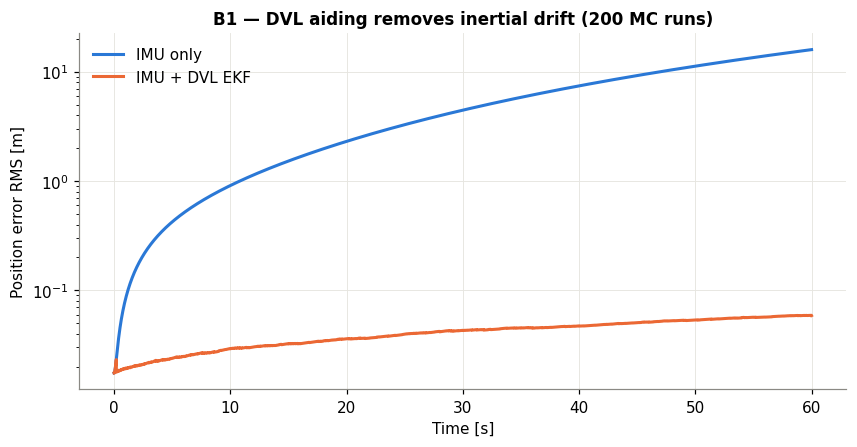

[B1] Final position RMSE IMU-only / IMU+DVL: 15.91 m / 0.059 m
[B1] Final velocity RMSE IMU-only / IMU+DVL: 0.518 / 0.0049 m/s
(4.9 s)


In [7]:
t0 = time.time()
o_ins = run_nav(N=200, dvl=False, seed=10); o_dvl = run_nav(N=200, seed=10)
fig, ax = plt.subplots()
ax.semilogy(o_ins["t"], rms3(o_ins["pos_err"]), label="IMU only")
ax.semilogy(o_dvl["t"], rms3(o_dvl["pos_err"]), label="IMU + DVL EKF")
ax.set(xlabel="Time [s]", ylabel="Position error RMS [m]", title="B1 — DVL aiding removes inertial drift (200 MC runs)"); ax.legend(); plt.show()
record("B1", "Final position RMSE IMU-only / IMU+DVL", f"{final_rmse(o_ins):.2f} m / {final_rmse(o_dvl):.3f} m")
record("B1", "Final velocity RMSE IMU-only / IMU+DVL", f"{final_rmse(o_ins,'vel_err'):.3f} / {final_rmse(o_dvl,'vel_err'):.4f} m/s")
print(f"({time.time()-t0:.1f} s)")

## B2. Random dropout and full DVL outages (old Exp 10, 12, 16, 17)

,dropout,final_pos_rmse,final_vel_rmse
0,0.00,0.0565,0.0049
1,0.15,0.0607,0.0052
2,0.30,0.0666,0.0055
3,0.50,0.0784,0.0060
4,0.80,0.1259,0.0084


,outage_s,pos_at_outage_end,pos_2s_after,vel_at_outage_end,vel_1s_after,final_pos
0,0,0.0378,0.0393,0.0050,0.0049,0.0574
1,5,0.0559,0.0523,0.0090,0.0064,0.0662
2,10,0.0993,0.0732,0.0120,0.0067,0.0806
3,20,0.1889,0.1317,0.0131,0.0065,0.1331
4,30,0.3036,0.2171,0.0139,0.0059,0.2161


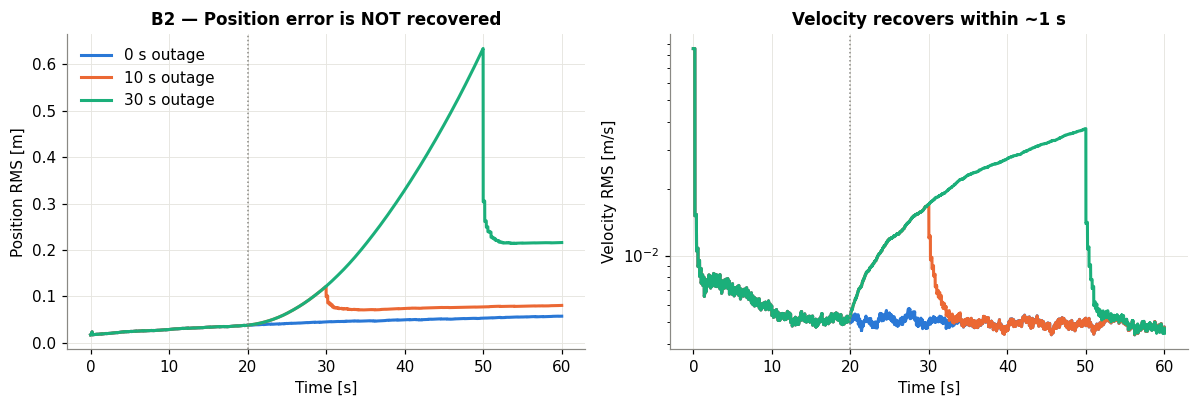

[B2] 50% random beam dropout final pos RMSE: 0.078 m
[B2] 30 s outage: pos at end / final; vel 1 s after: 0.30 m / 0.22 m; 0.0059 m/s


In [8]:
rows = []
for d in [0, 0.15, 0.3, 0.5, 0.8]:
    o = run_nav(N=100, dropout=d, seed=20); rows.append(dict(dropout=d, final_pos_rmse=final_rmse(o), final_vel_rmse=final_rmse(o, "vel_err")))
dfB2a = pd.DataFrame(rows); display(dfB2a)

rows = []; curves = {}
for L in [0, 5, 10, 20, 30]:
    o = run_nav(N=100, outage=(20, 20 + L) if L else None, seed=21)
    pe, ve = rms3(o["pos_err"]), rms3(o["vel_err"]); t = o["t"]; i_end = np.searchsorted(t, 20 + L)
    rows.append(dict(outage_s=L, pos_at_outage_end=pe[i_end], pos_2s_after=pe[min(i_end + 200, len(t) - 1)],
                     vel_at_outage_end=ve[i_end], vel_1s_after=ve[min(i_end + 100, len(t) - 1)], final_pos=pe[-1]))
    curves[L] = (t, pe, ve)
dfB2b = pd.DataFrame(rows); display(dfB2b)
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
for L in [0, 10, 30]:
    t, pe, ve = curves[L]; ax[0].plot(t, pe, label=f"{L} s outage"); ax[1].semilogy(t, ve, label=f"{L} s outage")
for a_ in ax: a_.axvline(20, color="#8a8984", ls=":", lw=1); a_.set_xlabel("Time [s]")
ax[0].set(ylabel="Position RMS [m]", title="B2 — Position error is NOT recovered"); ax[1].set(ylabel="Velocity RMS [m/s]", title="Velocity recovers within ~1 s")
ax[0].legend(); plt.tight_layout(); plt.show()
r30 = dfB2b[dfB2b.outage_s == 30].iloc[0]
record("B2", "50% random beam dropout final pos RMSE", f"{dfB2a[dfB2a.dropout==0.5].final_pos_rmse.iloc[0]:.3f} m")
record("B2", "30 s outage: pos at end / final; vel 1 s after", f"{r30.pos_at_outage_end:.2f} m / {r30.final_pos:.2f} m; {r30.vel_1s_after:.4f} m/s")

## B3. DVL update rate × IMU bias (old Exp 13–15)

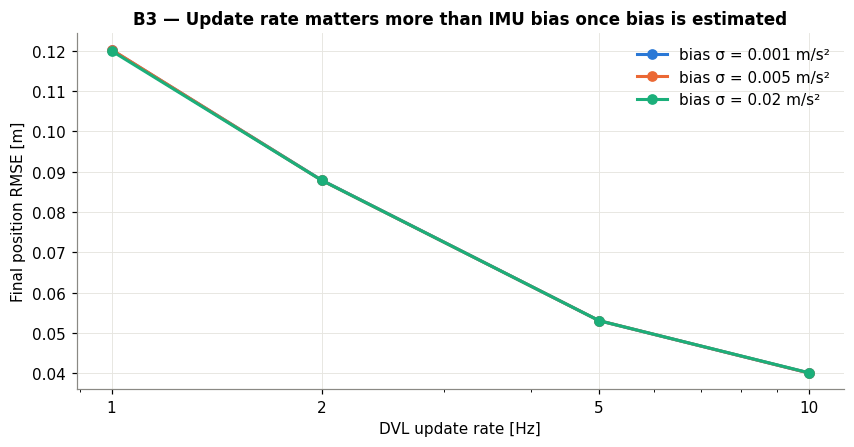

bias_sigma,0.001,0.005,0.020
dvl_rate,,,
1,0.1202,0.1203,0.1200
2,0.0880,0.0879,0.0879
5,0.0531,0.0531,0.0531
10,0.0401,0.0401,0.0402


[B3] Final pos RMSE 1 Hz vs 10 Hz (bias 0.005): 0.120 vs 0.040 m


In [9]:
rows = []
for bs in [0.001, 0.005, 0.02]:
    for rate in [1, 2, 5, 10]:
        o = run_nav(N=60, dvl_rate=rate, bias_sigma=bs, seed=30)
        rows.append(dict(bias_sigma=bs, dvl_rate=rate, final_pos_rmse=final_rmse(o), final_vel_rmse=final_rmse(o, "vel_err")))
dfB3 = pd.DataFrame(rows)
fig, ax = plt.subplots()
for bs in dfB3.bias_sigma.unique():
    d = dfB3[dfB3.bias_sigma == bs]; ax.plot(d.dvl_rate, d.final_pos_rmse, "o-", label=f"bias σ = {bs} m/s²")
ax.set(xscale="log", xlabel="DVL update rate [Hz]", ylabel="Final position RMSE [m]", title="B3 — Update rate matters more than IMU bias once bias is estimated")
ax.set_xticks([1, 2, 5, 10]); ax.set_xticklabels(["1", "2", "5", "10"]); ax.legend(); plt.show()
display(dfB3.pivot(index="dvl_rate", columns="bias_sigma", values="final_pos_rmse"))
record("B3", "Final pos RMSE 1 Hz vs 10 Hz (bias 0.005)", f"{dfB3.query('bias_sigma==0.005 & dvl_rate==1').final_pos_rmse.iloc[0]:.3f} vs {dfB3.query('bias_sigma==0.005 & dvl_rate==10').final_pos_rmse.iloc[0]:.3f} m")

## B4. Online accelerometer-bias estimation (old Exp 26E-type)
Compares a 9-state filter (estimates b_a) with the same filter with bias estimation switched off, using a large 0.02 m/s² bias.

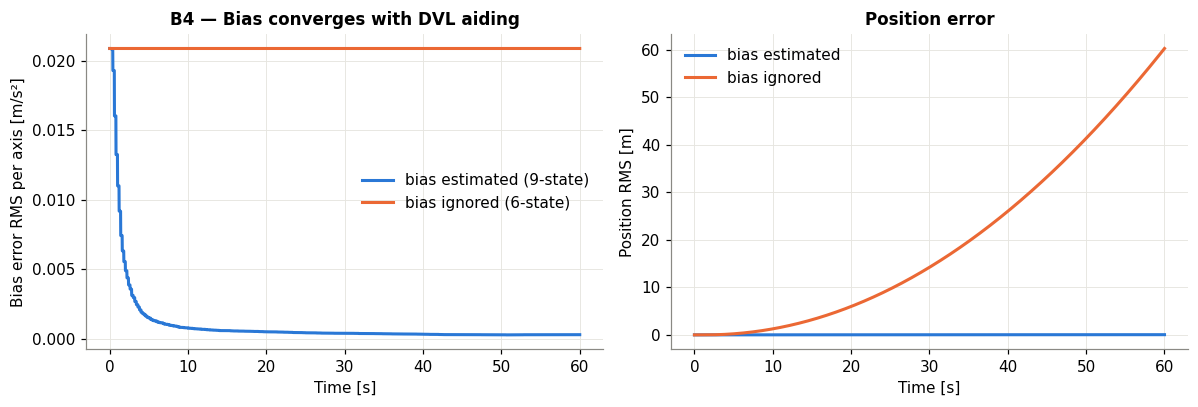

[B4] Final pos RMSE bias est. ON / OFF: 0.059 / 60.278 m
[B4] Normalised residual std ON / OFF (ideal 1.0): 1.00 / 50.85


In [10]:
o_on = run_nav(N=150, bias_sigma=0.02, estimate_bias=True, seed=40)
o_off = run_nav(N=150, bias_sigma=0.02, estimate_bias=False, seed=40)
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
ax[0].plot(o_on["t"], rms3(o_on["bias_err"]) / np.sqrt(3), label="bias estimated (9-state)")
ax[0].plot(o_off["t"], rms3(o_off["bias_err"]) / np.sqrt(3), label="bias ignored (6-state)")
ax[0].set(xlabel="Time [s]", ylabel="Bias error RMS per axis [m/s²]", title="B4 — Bias converges with DVL aiding"); ax[0].legend()
ax[1].plot(o_on["t"], rms3(o_on["pos_err"]), label="bias estimated"); ax[1].plot(o_off["t"], rms3(o_off["pos_err"]), label="bias ignored")
ax[1].set(xlabel="Time [s]", ylabel="Position RMS [m]", title="Position error"); ax[1].legend(); plt.tight_layout(); plt.show()
zstd_on, zstd_off = o_on["z"].std(), o_off["z"].std()
record("B4", "Final pos RMSE bias est. ON / OFF", f"{final_rmse(o_on):.3f} / {final_rmse(o_off):.3f} m")
record("B4", "Normalised residual std ON / OFF (ideal 1.0)", f"{zstd_on:.2f} / {zstd_off:.2f}")

## B5. Navigation with the noise the hardware can actually deliver
A3 shows that one 2 ms ping gives about 94 Hz of Doppler noise, while B1–B4 assume 10 Hz per update. Averaging `n` pings gives `σ_f / √n`, and `n` is fixed by the time budget:
* **Ping cycle at 20 m altitude:** two-way travel along the 30° slant (23.1 m), plus the 2 ms pulse and a 1 ms guard ≈ 34 ms.
* **Sequential beams** (one receive chain, the ₹10k design): each beam gets 1/4 of the pings.
* **Parallel beams** (four receive chains, about ₹2–3k more): every beam is pinged every cycle.

In [11]:
alt = 20.0; R_sl = alt / np.cos(np.radians(30)); T_ping = 2 * R_sl / CFG.c + 2e-3 + 1e-3
sig_ping = dfA3[(dfA3.method == "Dual-lag pulse-pair") & (dfA3.SNR_dB == 20)].sigma_Hz.iloc[0]
designs = [("Sequential, 5 Hz", 5, 4), ("Sequential, 2 Hz", 2, 4), ("Parallel, 5 Hz", 5, 1), ("Parallel, 2 Hz", 2, 1)]
rows = []
for name, rate, share in designs:
    n = (1 / rate) / T_ping / share
    hz = sig_ping / np.sqrt(n)
    o = run_nav(N=100, dvl_rate=rate, noise_hz=hz, seed=45)
    rows.append(dict(design=name, dvl_rate_Hz=rate, pings_per_beam=n, noise_Hz=hz, sigma_r_mps=sigma_v_from_hz(hz),
                     final_pos_rmse=final_rmse(o), final_vel_rmse=final_rmse(o, "vel_err"),
                     min_isolatable_fault_mps=6.7 * sigma_v_from_hz(hz)))
o_ref = run_nav(N=100, seed=45)
rows.append(dict(design="Idealised (B1–B4)", dvl_rate_Hz=5, pings_per_beam=np.nan, noise_Hz=10, sigma_r_mps=sigma_v_from_hz(10),
                 final_pos_rmse=final_rmse(o_ref), final_vel_rmse=final_rmse(o_ref, "vel_err"), min_isolatable_fault_mps=6.7 * sigma_v_from_hz(10)))
dfB5 = pd.DataFrame(rows); display(dfB5.round(4))
seq5 = dfB5.iloc[0]; par5 = dfB5.iloc[2]
record("B5", "Ping cycle @20 m / single-ping noise", f"{T_ping*1e3:.1f} ms / {sig_ping:.0f} Hz")
record("B5", "Sequential 5 Hz: noise / final pos RMSE (60 s)", f"{seq5.noise_Hz:.0f} Hz / {seq5.final_pos_rmse:.3f} m")
record("B5", "Parallel 5 Hz: noise / final pos RMSE (60 s)", f"{par5.noise_Hz:.0f} Hz / {par5.final_pos_rmse:.3f} m")

,design,dvl_rate_Hz,pings_per_beam,noise_Hz,sigma_r_mps,final_pos_rmse,final_vel_rmse,min_isolatable_fault_mps
0,"Sequential, 5 Hz",5,1.4796,77.2854,0.0580,0.4332,0.0170,0.3884
1,"Sequential, 2 Hz",2,3.6991,48.8796,0.0367,0.3843,0.0164,0.2456
2,"Parallel, 5 Hz",5,5.9186,38.6427,0.0290,0.2163,0.0107,0.1942
3,"Parallel, 2 Hz",2,14.7964,24.4398,0.0183,0.1942,0.0099,0.1228
4,Idealised (B1–B4),5,NaN,10.0000,0.0075,0.0587,0.0047,0.0502


[B5] Ping cycle @20 m / single-ping noise: 33.8 ms / 94 Hz
[B5] Sequential 5 Hz: noise / final pos RMSE (60 s): 77 Hz / 0.433 m
[B5] Parallel 5 Hz: noise / final pos RMSE (60 s): 39 Hz / 0.216 m


**Reading B5:**
* **The 10 Hz assumption is optimistic.** A real low-cost unit delivers about 40–80 Hz per update, 4–8× the idealised value.
* **Navigation still works.** The INS smooths the noise: after 60 s the position error is about 0.2–0.4 m instead of 0.06 m. That is still about 40× better than B1's 16 m IMU-only drift.
* **Fault detection gets coarser.** The smallest isolatable beam fault scales with σ_r (≈ 6.7·σ_r, from C2), so it rises from 0.05 m/s to roughly 0.2–0.4 m/s at 5 Hz.
* **Design decision:** four parallel receive chains cost about ₹2–3k more and roughly halve the noise. They are the best-value upgrade over the minimum build.
* The isolation column is scaled from the C2 results rather than simulated separately.

---
# Part C — Fault detection and isolation
## C1. Residual calibration on healthy data (fixes old Exp 26/26B, review item 26F-R)
The review's first required step is to check that healthy normalised residuals are N(0,1) **before** choosing a threshold.
* `ekf`: residual normalised by `b_iᵀ P_v⁻ b_i + σ_r²`, the correct form.
* `fixed`: residual normalised by σ_r only, which ignores INS uncertainty. This is the error behind the old high false-alarm results.

z_std           FA_4sigma            
normalisation     ekf   fixed         ekf       fixed
noise_Hz                                             
2              1.0001  1.3092  7.6271e-05  2.3390e-03
5              0.9994  1.1135  1.1017e-04  3.7288e-04
10             0.9993  1.0588  1.0169e-04  1.6949e-04
20             0.9994  1.0335  8.4746e-05  1.1864e-04
40             0.9996  1.0214  6.7797e-05  9.3220e-05

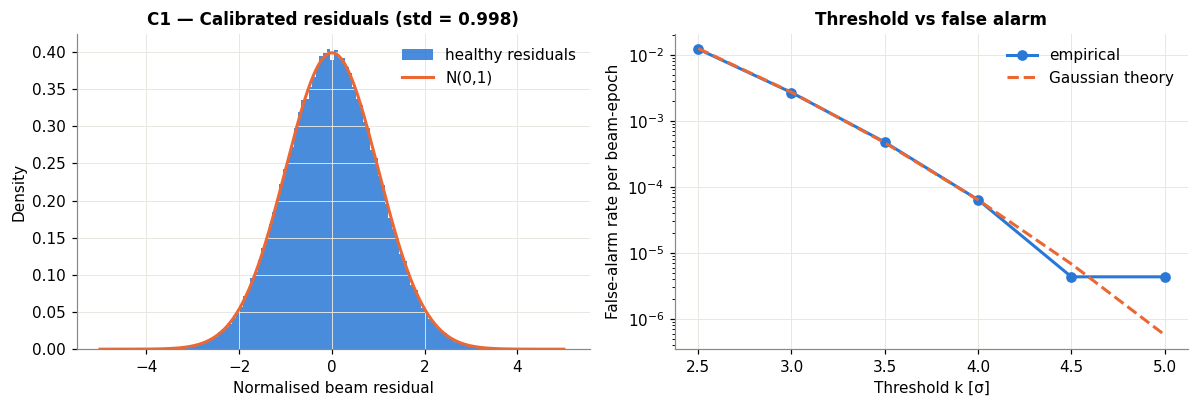

[C1] False alarm @4σ, 2 Hz noise: σ_r-only vs EKF-covariance: 0.23% vs 0.0076%
[C1] Healthy residual std (10 Hz, EKF norm.): 0.998


In [12]:
rows = []
for hz in [2, 5, 10, 20, 40]:
    for norm in ["ekf", "fixed"]:
        o = run_nav(N=100, noise_hz=hz, norm=norm, fdi=False, seed=50)
        z = o["z"][:, 5:].ravel()     # skip first second (initial transient)
        rows.append(dict(noise_Hz=hz, normalisation=norm, z_std=z.std(), FA_4sigma=np.mean(np.abs(z) > 4), FA_3sigma=np.mean(np.abs(z) > 3)))
dfC1 = pd.DataFrame(rows); display(dfC1.pivot(index="noise_Hz", columns="normalisation", values=["z_std", "FA_4sigma"]))

o = run_nav(N=200, noise_hz=10, fdi=False, seed=51); z = o["z"][:, 5:].ravel()
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
ax[0].hist(z, bins=120, density=True, color=PALETTE[0], alpha=0.85, label="healthy residuals")
zz = np.linspace(-5, 5, 300); ax[0].plot(zz, np.exp(-zz**2 / 2) / np.sqrt(2 * np.pi), color=PALETTE[1], label="N(0,1)")
ax[0].set(xlabel="Normalised beam residual", ylabel="Density", title=f"C1 — Calibrated residuals (std = {z.std():.3f})"); ax[0].legend()
ks = np.array([2.5, 3, 3.5, 4, 4.5, 5])
ax[1].semilogy(ks, [np.mean(np.abs(z) > k) + 1e-7 for k in ks], "o-", label="empirical")
ax[1].semilogy(ks, [erfc(k / sqrt(2)) for k in ks], "--", label="Gaussian theory")
ax[1].set(xlabel="Threshold k [σ]", ylabel="False-alarm rate per beam-epoch", title="Threshold vs false alarm"); ax[1].legend()
plt.tight_layout(); plt.show()
fa_fix = dfC1.query("noise_Hz==2 & normalisation=='fixed'").FA_4sigma.iloc[0]; fa_ekf = dfC1.query("noise_Hz==2 & normalisation=='ekf'").FA_4sigma.iloc[0]
record("C1", "False alarm @4σ, 2 Hz noise: σ_r-only vs EKF-covariance", f"{fa_fix:.2%} vs {fa_ekf:.4%}")
record("C1", "Healthy residual std (10 Hz, EKF norm.)", f"{z.std():.3f}")

## C2. Single-beam fault: detection and isolation vs fault size (old Exp 19C, 22–24, review stage 27)
A step bias is added to one randomly chosen beam from t = 30 s onward. The threshold is k = 4σ, with 2 s quarantine. Dashed lines show the same detector without quarantine.
* **Pd:** fraction of fault epochs in which the faulty beam is flagged.
* **Isolation:** fraction of fault epochs in which the faulty beam, and only that beam, is flagged.
* **FA:** rate of flags on healthy beams before the fault starts.

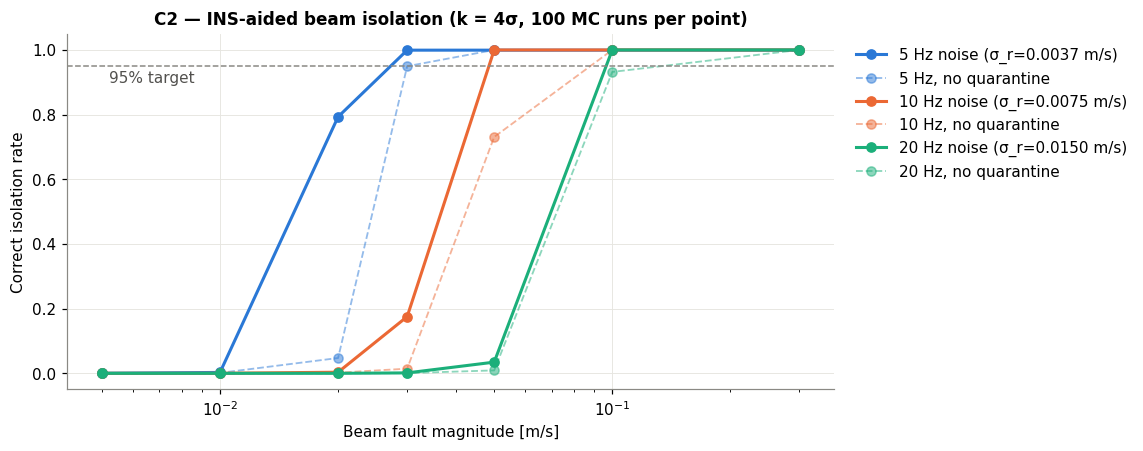

isolation                         isolation_no_quarantine  \
noise_Hz         5           10          20                      5    
fault_mps                                                             
0.005        0.0001  6.6225e-05  1.3245e-04                  0.0001   
0.010        0.0028  1.9868e-04  6.6225e-05                  0.0014   
0.020        0.7929  3.5099e-03  6.6225e-05                  0.0474   
0.030        0.9989  1.7530e-01  1.3907e-03                  0.9492   
0.050        0.9989  9.9947e-01  3.4636e-02                  0.9995   
0.100        0.9989  9.9954e-01  9.9954e-01                  0.9995   
0.300        0.9989  9.9954e-01  9.9960e-01                  0.9995   

                                   
noise_Hz           10          20  
fault_mps                          
0.005      6.6225e-05  1.3245e-04  
0.010      1.9868e-04  6.6225e-05  
0.020      2.0530e-03  6.6225e-05  
0.030      1.4503e-02  7.2848e-04  
0.050      7.3060e-01  9.1391e-03  
0.100      9.9954e-01  9.3159e-01  
0.300      9.9954e-01  9.9960e-01

[C2] Smallest fault isolated ≥95% @ 5 Hz: 0.03 m/s (FA 0.0017%)
[C2] Smallest fault isolated ≥95% @ 10 Hz: 0.05 m/s (FA 0.0000%)
[C2] Smallest fault isolated ≥95% @ 20 Hz: 0.1 m/s (FA 0.0000%)
[C2] 0.1 m/s beam fault: final pos RMSE without / with FDI: 3.132 / 0.070 m


In [13]:
rows = []
mags = [0.005, 0.01, 0.02, 0.03, 0.05, 0.1, 0.3]
for hz in [5, 10, 20]:
    for mag in mags:
        rng_f = np.random.default_rng(60); fb = rng_f.integers(0, 4, 100)
        o = run_nav(N=100, noise_hz=hz, fault=dict(beams=fb, mag=mag, t_start=30.0), seed=61)
        on = o["ep_t"] >= 30; fl, fy = o["excl"], o["faulty"]
        pd_ = fl[:, on][fy[:, on]].mean()
        iso = np.mean(np.all(fl[:, on] == fy[:, on], -1))
        fa = o["flag"][:, (~on) & (o["ep_t"] > 1)].mean()
        o0 = run_nav(N=100, noise_hz=hz, fault=dict(beams=fb, mag=mag, t_start=30.0), seed=61, hold_s=0.0)
        iso0 = np.mean(np.all(o0["excl"][:, on] == o0["faulty"][:, on], -1))
        rows.append(dict(noise_Hz=hz, fault_mps=mag, Pd=pd_, isolation=iso, isolation_no_quarantine=iso0, FA=fa, final_pos=final_rmse(o)))
dfC2 = pd.DataFrame(rows)
fig, ax = plt.subplots()
for hz in [5, 10, 20]:
    d = dfC2[dfC2.noise_Hz == hz]; col = PALETTE[[5, 10, 20].index(hz)]
    ax.plot(d.fault_mps, d.isolation, "o-", color=col, label=f"{hz} Hz noise (σ_r={sigma_v_from_hz(hz):.4f} m/s)")
    ax.plot(d.fault_mps, d.isolation_no_quarantine, "o--", color=col, alpha=0.5, lw=1.2, label=f"{hz} Hz, no quarantine")
ax.axhline(0.95, color="#8a8984", ls="--", lw=1); ax.text(0.0052, 0.9, "95% target", color="#52514e")
ax.set(xscale="log", xlabel="Beam fault magnitude [m/s]", ylabel="Correct isolation rate", title="C2 — INS-aided beam isolation (k = 4σ, 100 MC runs per point)")
ax.legend(loc="upper left", bbox_to_anchor=(1.01, 1)); plt.show()
display(dfC2.pivot(index="fault_mps", columns="noise_Hz", values=["isolation", "isolation_no_quarantine"]))
for hz in [5, 10, 20]:
    d = dfC2[(dfC2.noise_Hz == hz) & (dfC2.isolation >= 0.95)]
    record("C2", f"Smallest fault isolated ≥95% @ {hz} Hz", f"{d.fault_mps.min() if len(d) else '>0.3'} m/s (FA {dfC2[dfC2.noise_Hz==hz].FA.mean():.4%})")

o_nf = run_nav(N=100, fault=dict(beams=np.random.default_rng(60).integers(0, 4, 100), mag=0.1, t_start=30.0), fdi=False, seed=61)
o_f = run_nav(N=100, fault=dict(beams=np.random.default_rng(60).integers(0, 4, 100), mag=0.1, t_start=30.0), fdi=True, seed=61)
record("C2", "0.1 m/s beam fault: final pos RMSE without / with FDI", f"{final_rmse(o_nf):.3f} / {final_rmse(o_f):.3f} m")

## C3. Permanent beam failures (old Exp 21, review stage 29)
Beams are lost permanently at t = 10 s. The INS-aided filter keeps using whatever beams remain.

In [14]:
cases = {"none": (), "1 beam": (0,), "2 opposite (1,2)": (0, 1), "2 adjacent (1,3)": (0, 2), "3 beams": (0, 1, 2), "all 4": (0, 1, 2, 3)}
rows = []
for name, fbm in cases.items():
    o = run_nav(N=100, failed_beams=fbm, seed=70)
    e = o["pos_err"][:, -1]; ax_rmse = np.sqrt(np.mean(e**2, 0))
    rows.append(dict(case=name, final_pos_rmse=final_rmse(o), x=ax_rmse[0], y=ax_rmse[1], z=ax_rmse[2]))
dfC3 = pd.DataFrame(rows); display(dfC3)
record("C3", "Final pos RMSE: 0 / 1 / 2-opp / 2-adj / 3 / 4 beams lost", " / ".join(f"{v:.2f}" for v in dfC3.final_pos_rmse) + " m")

,case,final_pos_rmse,x,y,z
0,none,0.0563,0.0385,0.0371,0.0174
1,1 beam,0.0734,0.0601,0.0372,0.0199
2,"2 opposite (1,2)",1.1269,1.1261,0.0372,0.0200
3,"2 adjacent (1,3)",1.1161,0.7350,0.7263,0.4219
4,3 beams,1.5940,1.1261,0.9763,0.5655
5,all 4,1.9776,1.1261,1.2531,1.0358


[C3] Final pos RMSE: 0 / 1 / 2-opp / 2-adj / 3 / 4 beams lost: 0.06 / 0.07 / 1.13 / 1.12 / 1.59 / 1.98 m


**Reading C3:** each surviving beam constrains velocity along its own direction. With two opposite beams, only the y-axis (the direction no remaining beam sees) drifts. A tightly coupled, beam-level EKF therefore degrades **gracefully**, where the old "reconstruct 3-D velocity first" pipeline failed outright once two beams were lost.

## C4. Outliers and intermittent faults (review stage 28)

In [15]:
rows = []
scen = {"2% gross outliers (±0.5 m/s)": dict(outlier_p=0.02, outlier_mag=0.5),
        "intermittent 0.1 m/s (2 s on / 5 s)": dict(fault=dict(beams=np.random.default_rng(80).integers(0, 4, 100), mag=0.1, t_start=10.0, period=5.0, on=2.0))}
for name, kw in scen.items():
    for fdi in [False, True]:
        o = run_nav(N=100, fdi=fdi, seed=81, **kw)
        fy = o["faulty"]
        det = o["excl"][fy].mean() if fdi else np.nan
        fa = o["flag"][~fy].mean() if fdi else np.nan            # true false alarms: raw test on healthy beam-epochs
        lost = o["excl"][~fy].mean() if fdi else np.nan          # healthy data discarded (false alarms + quarantine)
        rows.append(dict(scenario=name, FDI=fdi, final_pos_rmse=final_rmse(o), final_vel_rmse=final_rmse(o, "vel_err"),
                         detect=det, FA=fa, healthy_data_discarded=lost))
dfC4 = pd.DataFrame(rows); display(dfC4)
for name in scen:
    d = dfC4[dfC4.scenario == name]
    record("C4", f"{name}: pos RMSE off→on FDI", f"{d.final_pos_rmse.iloc[0]:.3f} → {d.final_pos_rmse.iloc[1]:.3f} m (healthy data discarded {d.healthy_data_discarded.iloc[1]:.1%})")

,scenario,FDI,final_pos_rmse,final_vel_rmse,detect,FA,healthy_data_discarded
0,2% gross outliers (±0.5 m/s),False,0.4906,0.0385,NaN,NaN,NaN
1,2% gross outliers (±0.5 m/s),True,0.0588,0.0050,1.0,1.0210e-04,0.0089
2,intermittent 0.1 m/s (2 s on / 5 s),False,2.0995,0.0254,NaN,NaN,NaN
3,intermittent 0.1 m/s (2 s on / 5 s),True,0.0678,0.0052,1.0,4.5496e-05,0.0910


[C4] 2% gross outliers (±0.5 m/s): pos RMSE off→on FDI: 0.491 → 0.059 m (healthy data discarded 0.9%)
[C4] intermittent 0.1 m/s (2 s on / 5 s): pos RMSE off→on FDI: 2.099 → 0.068 m (healthy data discarded 9.1%)


---
# Part D — Deep water: 3800 m (Titanic) and 6000 m
## D1. Ocean environment
* **Sound speed:** Mackenzie (1981).
* **Absorption:** Francois–Garrison (1982).
* **Temperature profile:** a typical tropical profile, with a 28 °C mixed layer to 50 m, a thermocline, and about 1.5–2 °C at depth. S = 35 PSU.

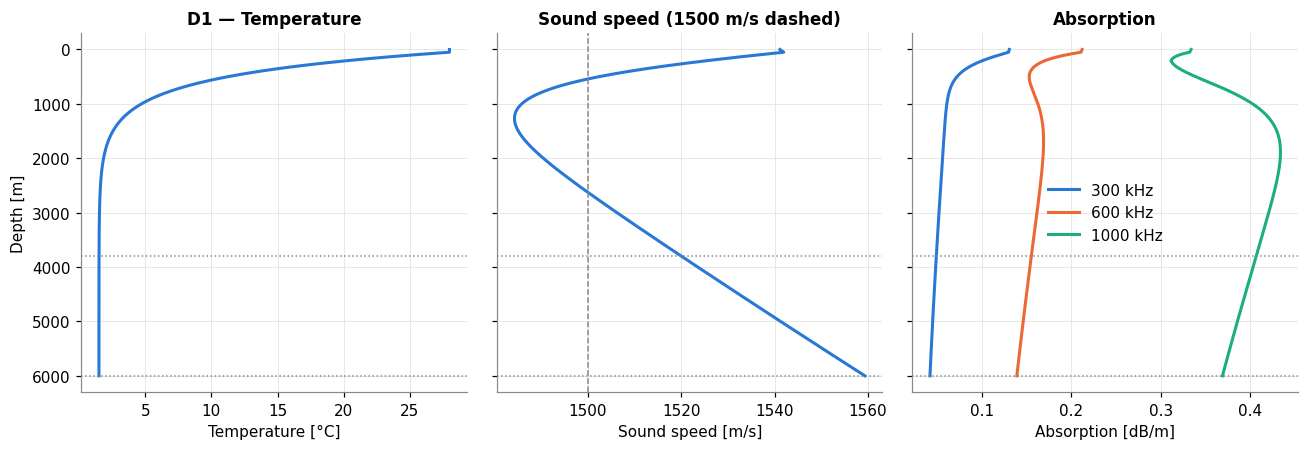

,depth_m,pressure_MPa,pressure_bar,T_C,c_mps,alpha_300kHz_dBm,alpha_600kHz_dBm,alpha_1000kHz_dBm
0,20,0.2015,2.0150,28.0000,1541.4621,0.1300,0.2114,0.3334
1,1000,10.0749,100.7487,4.7092,1485.8928,0.0604,0.1625,0.4030
2,3800,38.2845,382.8451,1.5064,1520.0559,0.0486,0.1550,0.4069
3,6000,60.4492,604.4922,1.5000,1559.3269,0.0415,0.1388,0.3692


[D1] Pressure / sound speed at 3800 m: 38.3 MPa / 1520.1 m/s
[D1] Pressure / sound speed at 6000 m: 60.4 MPa / 1559.3 m/s


In [16]:
def mackenzie(T, S, D):
    return (1448.96 + 4.591*T - 5.304e-2*T**2 + 2.374e-4*T**3 + 1.340*(S-35) + 1.630e-2*D + 1.675e-7*D**2
            - 1.025e-2*T*(S-35) - 7.139e-13*T*D**3)

def francois_garrison(f_khz, T, S, D, pH=8.0):
    """Absorption [dB/km]."""
    c = 1412 + 3.21*T + 1.19*S + 0.0167*D; f = f_khz
    A1 = 8.86/c * 10**(0.78*pH - 5); f1 = 2.8*np.sqrt(S/35) * 10**(4 - 1245/(T + 273))
    A2 = 21.44*S/c * (1 + 0.025*T); P2 = 1 - 1.37e-4*D + 6.2e-9*D**2; f2 = 8.17*10**(8 - 1990/(T + 273)) / (1 + 0.0018*(S - 35))
    P3 = 1 - 3.83e-5*D + 4.9e-10*D**2
    A3 = np.where(T <= 20, 4.937e-4 - 2.59e-5*T + 9.11e-7*T**2 - 1.5e-8*T**3, 3.964e-4 - 1.146e-5*T + 1.45e-7*T**2 - 6.5e-10*T**3)
    return A1*f1*f**2/(f1**2 + f**2) + A2*P2*f2*f**2/(f2**2 + f**2) + A3*P3*f**2

def temp_profile(z):
    z = np.asarray(z, float)
    return np.where(z < 50, 28.0, 1.5 + 26.5*np.exp(-(z - 50)/450))

z = np.linspace(0, 6000, 601); Tz = temp_profile(z); cz = mackenzie(Tz, 35, z)
fig, ax = plt.subplots(1, 3, figsize=(12, 4.2), sharey=True)
ax[0].plot(Tz, z); ax[0].set(xlabel="Temperature [°C]", ylabel="Depth [m]", title="D1 — Temperature")
ax[1].plot(cz, z); ax[1].axvline(1500, color="#8a8984", ls="--", lw=1); ax[1].set(xlabel="Sound speed [m/s]", title="Sound speed (1500 m/s dashed)")
for f in [300, 600, 1000]: ax[2].plot(francois_garrison(f, Tz, 35, z)/1000, z, label=f"{f} kHz")
ax[2].set(xlabel="Absorption [dB/m]", title="Absorption"); ax[2].legend()
ax[0].invert_yaxis()
for d in [3800, 6000]:
    for a_ in ax: a_.axhline(d, color="#8a8984", ls=":", lw=1)
plt.tight_layout(); plt.show()
env = pd.DataFrame([dict(depth_m=d, pressure_MPa=1027*9.81*d/1e6, pressure_bar=1027*9.81*d/1e5, T_C=float(temp_profile(d)),
                         c_mps=float(mackenzie(temp_profile(d), 35, d)),
                         **{f"alpha_{f}kHz_dBm": float(francois_garrison(f, temp_profile(d), 35, d)/1000) for f in [300, 600, 1000]})
                    for d in [20, 1000, 3800, 6000]]); display(env)
record("D1", "Pressure / sound speed at 3800 m", f"{env.pressure_MPa[2]:.1f} MPa / {env.c_mps[2]:.1f} m/s")
record("D1", "Pressure / sound speed at 6000 m", f"{env.pressure_MPa[3]:.1f} MPa / {env.c_mps[3]:.1f} m/s")

## D2. Sound-speed error
With a flat-piston transducer, the DVL velocity scales directly with the assumed c: `v̂ = v · c_assumed / c_true`. Two cases are compared:
* **Uncorrected:** the DVL assumes c = 1500 m/s.
* **Corrected:** c is computed from the onboard temperature and depth sensors (Bar30) with Mackenzie. Residual error comes from ±0.5 °C temperature and ±1 m depth uncertainty.

In [17]:
rows = []
for d in [20, 1000, 3800, 6000]:
    T_ = float(temp_profile(d)); c_true = float(mackenzie(T_, 35, d))
    scale_unc = 1500/c_true - 1
    rr = np.random.default_rng(90); c_est = mackenzie(T_ + rr.normal(0, 0.5, 20000), 35 + rr.normal(0, 0.5, 20000), d + rr.normal(0, 1, 20000))
    scale_cor = np.std(c_est/c_true - 1)
    rows.append(dict(depth_m=d, c_true=c_true, scale_err_uncorrected_pct=100*scale_unc, err_per_km_uncorrected_m=1000*abs(scale_unc),
                     scale_err_corrected_pct=100*scale_cor, err_per_km_corrected_m=1000*scale_cor))
dfD2 = pd.DataFrame(rows); display(dfD2)
record("D2", "Velocity scale error if c=1500 assumed @3800/6000 m", f"{dfD2.scale_err_uncorrected_pct[2]:.2f}% / {dfD2.scale_err_uncorrected_pct[3]:.2f}% ({dfD2.err_per_km_uncorrected_m[2]:.0f}/{dfD2.err_per_km_uncorrected_m[3]:.0f} m per km)")
record("D2", "After Mackenzie correction (T±0.5°C)", f"~{dfD2.scale_err_corrected_pct[2]:.2f}% ({dfD2.err_per_km_corrected_m[2]:.1f} m per km)")

,depth_m,c_true,scale_err_uncorrected_pct,err_per_km_uncorrected_m,scale_err_corrected_pct,err_per_km_corrected_m
0,20,1541.4621,-2.6898,26.8979,0.0779,0.7794
1,1000,1485.8928,0.9494,9.4941,0.1440,1.4398
2,3800,1520.0559,-1.3194,13.1942,0.1501,1.5005
3,6000,1559.3269,-3.8046,38.0465,0.1428,1.4278


[D2] Velocity scale error if c=1500 assumed @3800/6000 m: -1.32% / -3.80% (13/38 m per km)
[D2] After Mackenzie correction (T±0.5°C): ~0.15% (1.5 m per km)


## D3. Bottom-lock range vs carrier frequency (sonar equation)
`SNR = SL − 2·TL + S_b + 10·log₁₀(A) − (NL + 10·log₁₀ BW + NF)`
* `TL = 20·log₁₀ R + α R`.
* `A` is the footprint area, limited by either the beam width or the pulse length.
* Noise is thermal sea noise plus a 6 dB receiver noise figure.

**Assumptions (low-cost DIY unit):** SL = 205 dB re 1 µPa @ 1 m, 4° beams, 1 ms pulse, seabed S_b = −27 dB, 10 dB SNR needed for lock. Keeping a 4° beam at 300 kHz needs a disc about 67 mm across, versus about 20 mm at 1 MHz.

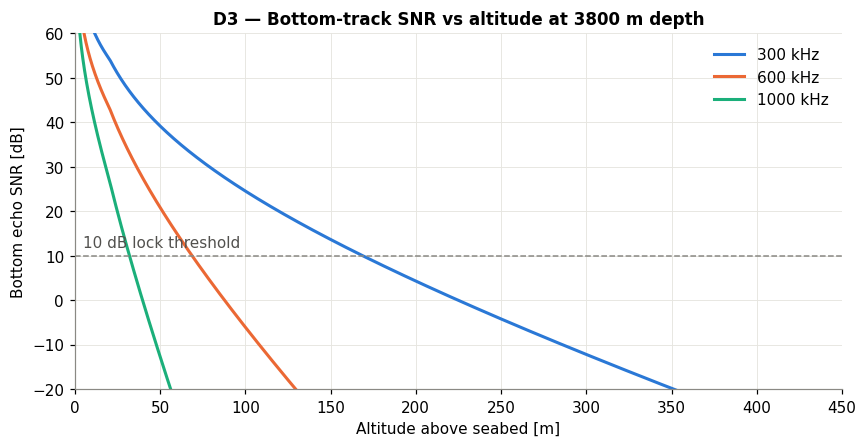

,freq_kHz,site_depth_m,max_slant_m,max_altitude_m
0,300,20,104.0927,90.1469
1,300,3800,195.0190,168.8914
2,600,20,64.6115,55.9552
3,600,3800,79.3671,68.7339
4,1000,20,42.4782,36.7872
5,1000,3800,36.8950,31.9520


[D3] Max bottom-lock altitude @3800 m: 300/600/1000 kHz: 169 / 69 / 32 m


In [18]:
def bottom_snr(R, f_khz, T, D, SL=205.0, beam_deg=4.0, theta=30.0, tau=1e-3, NF=6.0, Sb=-27.0, c=1500.0):
    alpha = francois_garrison(f_khz, T, 35, D)/1000
    TL = 20*np.log10(R) + alpha*R; psi = np.radians(beam_deg)
    A = np.minimum(np.pi*(R*np.tan(psi/2))**2/np.cos(np.radians(theta)), (c*tau/2)/np.sin(np.radians(theta))*R*psi)
    NL = -15 + 20*np.log10(f_khz) + 10*np.log10(1/tau) + NF
    return SL - 2*TL + Sb + 10*np.log10(A) - NL

R = np.linspace(2, 600, 3000); rows = []
fig, ax = plt.subplots()
for i, f in enumerate([300, 600, 1000]):
    for d, ls in [(20, ":"), (3800, "-")]:
        snr = bottom_snr(R, f, float(temp_profile(d)), d)
        if d == 3800: ax.plot(R*np.cos(np.radians(30)), snr, ls, color=PALETTE[i], label=f"{f} kHz")
        ok = R[snr >= 10]; rmax = ok.max() if len(ok) else 0
        rows.append(dict(freq_kHz=f, site_depth_m=d, max_slant_m=rmax, max_altitude_m=rmax*np.cos(np.radians(30))))
ax.axhline(10, color="#8a8984", ls="--", lw=1); ax.text(5, 12, "10 dB lock threshold", color="#52514e")
ax.set(xlabel="Altitude above seabed [m]", ylabel="Bottom echo SNR [dB]", title="D3 — Bottom-track SNR vs altitude at 3800 m depth", ylim=(-20, 60), xlim=(0, 450)); ax.legend(); plt.show()
dfD3 = pd.DataFrame(rows); display(dfD3)
H_LOCK = {f: dfD3.query("freq_kHz==@f & site_depth_m==3800").max_altitude_m.iloc[0] for f in [300, 600, 1000]}
record("D3", "Max bottom-lock altitude @3800 m: 300/600/1000 kHz", " / ".join(f"{H_LOCK[f]:.0f}" for f in [300, 600, 1000]) + " m")

## D4. Mission error budget: descent to 3800 / 6000 m, then a 1-hour survey
**Profile:** a vertical descent at 1 m/s, then a 1-hour lawnmower survey at 1.5 m/s (500 m legs, 50 m spacing). 500 Monte-Carlo runs.

**During descent** the DVL is out of bottom range for almost the whole water column. Three ways to navigate it:
* **INS-only:** position error grows as ½·b·t² from an IMU bias that cannot be observed.
* **Water-track:** the DVL measures velocity relative to the surrounding water. The unknown ocean current (Gauss–Markov in depth, σ = 0.10 m/s, 300 m correlation) is integrated as error.
* **Bottom-track:** only within the last `h_lock` metres (from D3).

**During the survey:** heading error (a constant bias plus a heading-dependent deviation) and the velocity scale error from D2.
* **MEMS** heading: 1° bias, 1° deviation. **FOG** heading: 0.05° bias, 0.02° deviation.
* Table columns: `lock_m` = bottom-lock altitude, `c_corr` = sound speed corrected, `INS_only_m` / `watertrack_m` = error at touchdown, `survey_m` = error added by the 1-h survey, `total_m` = water-track descent + survey.

,depth_m,freq_kHz,lock_m,heading,c_corr,INS_only_m,watertrack_m,survey_m,total_m
0,3800,1000,32,MEMS,False,51555.6,200.1,63.5,212.8
1,3800,1000,32,MEMS,True,51555.6,200.1,60.9,210.2
2,3800,1000,32,FOG,False,51555.6,200.1,6.0,200.3
3,3800,1000,32,FOG,True,51555.6,200.1,1.3,200.1
4,3800,300,169,MEMS,False,51328.5,193.4,60.5,200.7
5,3800,300,169,MEMS,True,51328.5,193.4,64.9,205.3
6,3800,300,169,FOG,False,51328.5,193.4,6.1,193.3
7,3800,300,169,FOG,True,51328.5,193.4,1.3,193.3
8,6000,1000,32,MEMS,False,122476.3,263.8,62.8,268.2
9,6000,1000,32,MEMS,True,122476.3,263.8,58.6,272.0


[D4] 3800 m touchdown error: INS-only / water-track: 51.6 km / 200 m
[D4] 1-h survey error MEMS vs FOG heading (c corrected): 60.9 m vs 1.3 m
[D4] 3800 m water-track touchdown error 1 MHz vs 300 kHz: 200 m vs 193 m


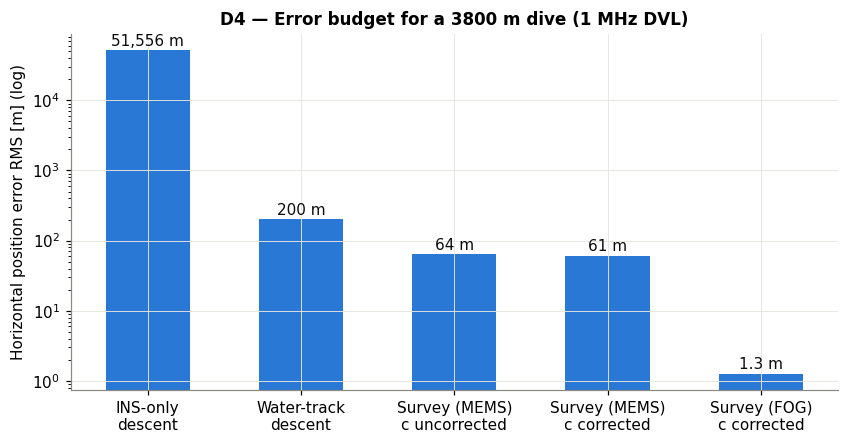

In [19]:
def descent_error(depth, h_lock, N, rng, v_desc=1.0, sig_cur=0.10, Lc=300.0, dz=5.0, mode="water"):
    n = int((depth - h_lock)/dz); rho = np.exp(-dz/Lc)
    if mode == "ins":
        Td = depth/v_desc; return 0.5*rng.normal(0, CFG.sigma_bias, (N, 2))*Td**2
    cur = np.zeros((N, 2)); cur[:] = rng.normal(0, sig_cur, (N, 2)); err = np.zeros((N, 2))
    for _ in range(n):
        err += cur*dz/v_desc
        cur = rho*cur + np.sqrt(1 - rho**2)*rng.normal(0, sig_cur, (N, 2))
    return err      # bottom-track segment adds negligible error

def survey_error(N, rng, heading_bias_deg, heading_dev_deg, scale_sd, scale_bias=0.0, v=1.5, leg=500.0, spacing=50.0, T=3600.0, dt=1.0):
    t = np.arange(0, T, dt); s = v*t; leg_len = leg + spacing; k = (s // leg_len).astype(int); u = s % leg_len
    hdg = np.where(u < leg, np.where(k % 2 == 0, 0.0, np.pi), np.pi/2)
    vel = v*np.stack([np.cos(hdg), np.sin(hdg)], 1)
    hb = np.radians(rng.normal(0, heading_bias_deg, (N, 1))); hd = np.radians(rng.normal(0, heading_dev_deg, (N, 1))); ph = rng.uniform(0, 2*np.pi, (N, 1))
    e_h = hb + hd*np.sin(hdg[None, :] + ph); sc = 1 + scale_bias + rng.normal(0, scale_sd, (N, 1))
    ch, sh = np.cos(hdg[None, :] + e_h), np.sin(hdg[None, :] + e_h)
    v_est = sc[..., None]*v*np.stack([ch, sh], -1)
    return (v_est - vel[None]).sum(1)*dt

grades = {"MEMS": (1.0, 1.0), "FOG": (0.05, 0.02)}   # heading error: (bias, heading-dependent deviation) in degrees
rows = []; rng = np.random.default_rng(100); Nmc = 500
for depth in [3800, 6000]:
    c_true = float(mackenzie(temp_profile(depth), 35, depth))
    for f in [1000, 300]:
        hl = H_LOCK[f]
        e_ins = descent_error(depth, hl, Nmc, rng, mode="ins"); e_wt = descent_error(depth, hl, Nmc, rng, mode="water")
        for gname, (hb, hd) in grades.items():
            for corr in [False, True]:
                es = survey_error(Nmc, rng, hb, hd, scale_sd=0.0007 if corr else 0.0, scale_bias=0.0 if corr else 1500/c_true - 1)
                rows.append(dict(depth_m=depth, freq_kHz=f, lock_m=round(hl), heading=gname, c_corr=corr,
                                 INS_only_m=np.sqrt(np.mean(np.sum(e_ins**2, 1))),
                                 watertrack_m=np.sqrt(np.mean(np.sum(e_wt**2, 1))),
                                 survey_m=np.sqrt(np.mean(np.sum(es**2, 1))),
                                 total_m=np.sqrt(np.mean(np.sum((e_wt + es)**2, 1)))))
dfD4 = pd.DataFrame(rows)
display(dfD4.round(1))
pick = dfD4.query("depth_m==3800 & freq_kHz==1000 & c_corr").set_index("heading")
record("D4", "3800 m touchdown error: INS-only / water-track", f"{pick.INS_only_m.iloc[0]/1000:.1f} km / {pick.watertrack_m.iloc[0]:.0f} m")
record("D4", "1-h survey error MEMS vs FOG heading (c corrected)", f"{pick.survey_m.loc['MEMS']:.1f} m vs {pick.survey_m.loc['FOG']:.1f} m")
w3 = dfD4.query("depth_m==3800 & c_corr").groupby("freq_kHz").watertrack_m.mean()
record("D4", "3800 m water-track touchdown error 1 MHz vs 300 kHz", f"{w3[1000]:.0f} m vs {w3[300]:.0f} m")

fig, ax = plt.subplots()
labels = ["INS-only\ndescent", "Water-track\ndescent", "Survey (MEMS)\nc uncorrected", "Survey (MEMS)\nc corrected", "Survey (FOG)\nc corrected"]
d38 = dfD4.query("depth_m==3800 & freq_kHz==1000")
vals = [d38.INS_only_m.iloc[0], d38.watertrack_m.iloc[0],
        d38[(d38.heading == "MEMS") & ~d38.c_corr].survey_m.iloc[0],
        d38[(d38.heading == "MEMS") & d38.c_corr].survey_m.iloc[0],
        d38[(d38.heading == "FOG") & d38.c_corr].survey_m.iloc[0]]
ax.bar(labels, vals, color=PALETTE[0], width=0.55); ax.set_yscale("log")
for i, v_ in enumerate(vals): ax.text(i, v_*1.15, f"{v_:,.0f} m" if v_ >= 10 else f"{v_:.1f} m", ha="center", color="#0b0b0b")
ax.set(ylabel="Horizontal position error RMS [m] (log)", title="D4 — Error budget for a 3800 m dive (1 MHz DVL)"); plt.show()

**Reading D4:**
* **The descent dominates.** A MEMS INS alone drifts tens of kilometres over a 1-hour descent. Water-tracking reduces that to hundreds of metres. No DVL frequency fixes this, because absolute position at the seabed needs an acoustic positioning fix (USBL or LBL) or terrain matching.
* **Frequency barely matters for touchdown error.** A 300 kHz unit locks onto the bottom about 100+ m earlier, which removes only a few percent of the descent.
* **On the seabed, heading accuracy and sound-speed correction matter most.** Correcting c with Mackenzie and the Bar30 temperature is free and removes a 1.3–3.8% scale error (D2). The heading sensor (MEMS vs FOG) then dominates survey drift.

## D5. Pressure housing sizing vs pressure-tolerant design
The required wall thickness is the larger of two limits, for an 80 mm ID × 200 mm long DVL electronics housing:
* **Yield (Lamé thick-wall), safety factor 1.5.**
* **Elastic buckling of a short tube between end caps (Windenburg–Trilling), safety factor 3:** `p_cr = 2.42·E·(t/D)^2.5 / [(1−ν²)^0.75·(L/D − 0.45·√(t/D))]`.

These are first-pass numbers. End caps, O-ring glands, penetrators and fatigue need FEA.

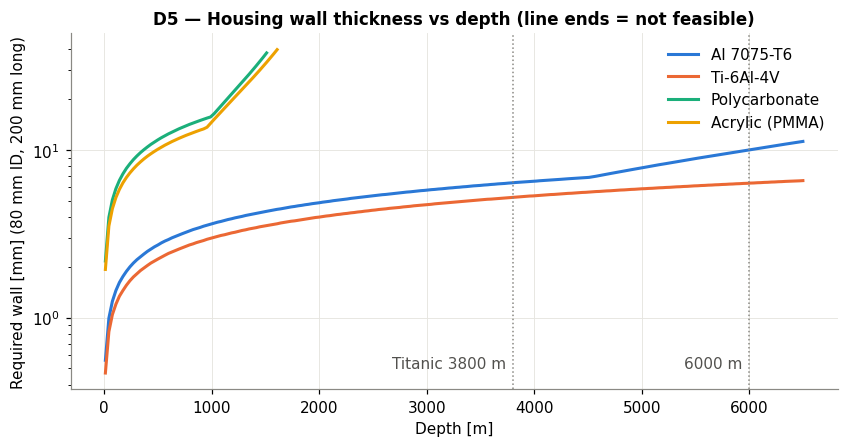

,material,depth_m,wall_mm,tube_mass_kg,net_buoyancy_kg
0,Al 7075-T6,300,2.21,0.32,0.83
1,Al 7075-T6,3800,6.38,0.97,0.42
2,Al 7075-T6,6000,10.02,1.59,0.02
3,Ti-6Al-4V,300,1.82,0.42,0.71
4,Ti-6Al-4V,3800,5.23,1.24,0.08
5,Ti-6Al-4V,6000,6.34,1.52,-0.14
6,Polycarbonate,300,9.17,0.62,0.94
7,Polycarbonate,3800,NaN,NaN,NaN
8,Polycarbonate,6000,NaN,NaN,NaN
9,Acrylic (PMMA),300,8.08,0.53,0.96


[D5] Wall @ 3800 m: Al7075 / Ti64 / PC: 6.4 mm / 5.2 mm / not feasible
[D5] Wall @ 6000 m: Al7075 / Ti64 / PC: 10.0 mm / 6.3 mm / not feasible
[D5] Example 150 mm PC tube hull (5 mm wall): collapse / safe (SF 2): ~25 m / ~12 m


In [20]:
mats = {"Al 7075-T6": (503e6, 71.7e9, 0.33, 2810), "Ti-6Al-4V": (880e6, 113.8e9, 0.342, 4430),
        "Polycarbonate": (62e6, 2.4e9, 0.37, 1200), "Acrylic (PMMA)": (65e6, 3.2e9, 0.37, 1190)}
a_in, L_h = 0.040, 0.200
def p_buckle(t, a, L, E, nu):
    D = 2*a + 2*t; td = t/D
    return 2.42*E*td**2.5/((1 - nu**2)**0.75*(L/D - 0.45*np.sqrt(td)))
def p_yield(t, a, Sy):
    b = a + t; return Sy*(b**2 - a**2)/(2*b**2)
def wall_required(p, Sy, E, nu, SFy=1.5, SFb=3.0, a=a_in, L=L_h):
    ts = np.linspace(0.0002, a, 4000)
    ok = (p_yield(ts, a, Sy)/SFy >= p) & (p_buckle(ts, a, L, E, nu)/SFb >= p)
    return ts[np.argmax(ok)] if ok.any() else np.nan
depths = np.linspace(10, 6500, 200)
fig, ax = plt.subplots(); rows = []
for i, (m, (Sy, E, nu, rho_m)) in enumerate(mats.items()):
    tw = np.array([wall_required(1027*9.81*d, Sy, E, nu) for d in depths])
    ax.plot(depths, tw*1000, color=PALETTE[i], label=m)
    for d in [300, 3800, 6000]:
        t_ = wall_required(1027*9.81*d, Sy, E, nu)
        mass = np.pi*((a_in + t_)**2 - a_in**2)*L_h*rho_m
        disp = np.pi*(a_in + t_)**2*L_h*1027
        rows.append(dict(material=m, depth_m=d, wall_mm=t_*1000, tube_mass_kg=mass, net_buoyancy_kg=disp - mass))
for d, lab in [(3800, "Titanic 3800 m"), (6000, "6000 m")]:
    ax.axvline(d, color="#8a8984", ls=":", lw=1); ax.text(d - 60, 0.5, lab, color="#52514e", ha="right")
ax.set(yscale="log", xlabel="Depth [m]", ylabel="Required wall [mm] (80 mm ID, 200 mm long)", title="D5 — Housing wall thickness vs depth (line ends = not feasible)"); ax.legend(); plt.show()
dfD5 = pd.DataFrame(rows); display(dfD5.round(2))
fmt = lambda v: "not feasible" if np.isnan(v) else f"{v:.1f} mm"
for d in [3800, 6000]:
    q = dfD5[dfD5.depth_m == d].set_index("material").wall_mm
    record("D5", f"Wall @ {d} m: Al7075 / Ti64 / PC", f"{fmt(q['Al 7075-T6'])} / {fmt(q['Ti-6Al-4V'])} / {fmt(q['Polycarbonate'])}")

# Example: why a typical hobby-AUV hull cannot go deep.
# A 150 mm OD x 800 mm polycarbonate tube with a 5 mm wall, end caps only, no internal rings.
OD, t_hull, L_hull = 0.150, 0.005, 0.800
Sy, E, nu, _ = mats["Polycarbonate"]; a_h = OD/2 - t_hull
p_c = min(p_yield(t_hull, a_h, Sy), p_buckle(t_hull, a_h, L_hull, E, nu))
record("D5", "Example 150 mm PC tube hull (5 mm wall): collapse / safe (SF 2)", f"~{p_c/(1027*9.81):.0f} m / ~{p_c/2/(1027*9.81):.0f} m")

### Pressure-tolerant alternative (recommended for the low-cost DVL)
A fully potted DVL contains no air, so there is no pressure difference across it and no wall to size. The design rules:
* Solid-backed PZT transducers.
* No electrolytic capacitors, no hollow-can crystals (use a MEMS oscillator), no relays.
* Polyurethane potting, vacuum-degassed.
* Cable potted directly into the block, with no connector.

The parts cost is almost the same at 3800 m and 6000 m. What changes is the test pressure.

| Route | 3800 m (≈ 38 MPa) | 6000 m (≈ 60 MPa) |
|---|---|---|
| Pressure-tolerant (potted) DIY DVL | ₹15–25k | ₹20–30k |
| Al 7075 housing + deep-rated connectors | ₹0.6–1.2 L | ₹1–1.5 L |
| Ti-6Al-4V housing + deep-rated connectors | ₹1–2 L | ₹1.5–3 L |
| Hyperbaric qualification test | depends on facility | fewer facilities reach 600 bar |

*Indicative Indian prices (2026). Confirm against supplier quotes before ordering.*

---
# Part E — Summary of results

In [21]:
summary = pd.DataFrame(RESULTS, columns=["Experiment", "Metric", "Result"])
with pd.option_context("display.max_colwidth", 120):
    display(summary.style.hide(axis="index").set_properties(**{"text-align": "left"}))

Experiment,Metric,Result
A1,Doppler shift for v_r = 0.5 m/s @ 1 MHz,666.667 Hz
A1,σ_v for 10 Hz Doppler noise,0.0075 m/s (MC 0.0075)
A2,κ(4 beams) / κ(3 beams),2.449 / 3.821; 2 beams → rank 2 (unobservable alone)
A2,"LS reconstruction RMSE [Vx,Vy,Vz] @10 Hz",[0.01065 0.01059 0.00433]
A3,Single-ping σ_f at 20 dB (dual-lag PP),94.0 Hz → ~89 pings averaged per beam to reach 10 Hz
A3,Altitude RMSE at 20 dB (MF),0.211 m @ 20 m
B1,Final position RMSE IMU-only / IMU+DVL,15.91 m / 0.059 m
B1,Final velocity RMSE IMU-only / IMU+DVL,0.518 / 0.0049 m/s
B2,50% random beam dropout final pos RMSE,0.078 m
B2,30 s outage: pos at end / final; vel 1 s after,0.30 m / 0.22 m; 0.0059 m/s


### Conclusions
1. **Measurement.** With the 30° Janus geometry, 10 Hz Doppler noise gives about 0.0075 m/s per beam. The design tolerates the loss of any single beam (κ 2.45 → 3.82). A single 2 ms ping is speckle-limited, so the firmware must average pings or use coded pulses. Use dual-lag pulse-pair on the MCU rather than an FFT.
2. **Navigation.** DVL aiding turns metre-level INS drift into centimetre-level error. With the noise a low-cost unit can actually deliver (B5), the error stays at the decimetre level. Bias estimation keeps the filter consistent. After outages, velocity recovers quickly, but position error from the outage is permanent.
3. **Fault tolerance.** Normalising beam residuals with the EKF covariance makes them N(0,1), which fixes the old Exp 26/26B false-alarm problem. With that fix, INS-aided isolation catches faults of a few cm/s at k = 4σ. Beam-level fusion keeps navigating even with 2–3 beams lost.
4. **Deep water.**
   * The electronics problem is pressure, solved by a pressure-tolerant design.
   * The navigation problem is the descent, which needs USBL/LBL or water-track for absolute position.
   * The measurement problem is sound speed, solved by the Mackenzie correction.
   * A 1 MHz DVL locks onto the bottom from only a few tens of metres; 300 kHz extends that but barely changes touchdown error.

**Next steps:** run this pipeline on recorded echoes from the hardware prototype (bucket → pool → lake), then move it to ROS 2 / Gazebo.